# Лабораторная работа 1. Линейная регрессия: RiskScore
Разделы: 1) EDA (отдельный ноутбук) · 2) нормализация и метрики · 3) класс линейной регрессии (analytic / GD / SGD, L1 / L2 / L1+L2) · 4) кросс-валидация и итоговая модель.

# Лабораторная работа 1. Часть 1: нормализация и метрики
Все алгоритмы реализованы вручную на NumPy; sklearn используется только для проверки.

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

DATA_DIR = "data"

## Подготовка данных
Убираем полностью пустые строки, аномальные значения цели (±1e7), точные дубли и строки с пропусками.
Дубли удаляем до любых разбиений, иначе одинаковые строки попадут и в обучение, и в проверку.

In [2]:
raw = pd.read_csv(f"{DATA_DIR}/train.csv")
ok = raw["RiskScore"].notna() & (raw["RiskScore"].abs() < 1e6)
data = raw[ok].drop_duplicates().dropna().reset_index(drop=True)
print(f"было {len(raw)}, осталось {len(data)}")

num_cols = [c for c in data.select_dtypes("number").columns if c != "RiskScore"]
X_demo = data[num_cols].to_numpy(dtype=float)
y_demo = data["RiskScore"].to_numpy(dtype=float)
X_demo.shape

было 11017, осталось 9332


(9332, 28)

## 1. Нормализация
* **z-score:** `z = (x − μ) / σ` (σ с делителем n, как в sklearn);
* **min-max:** `x' = (x − min) / (max − min)`.

Параметры считаются только по обучающей выборке (`fit`), а затем применяются к любым данным (`transform`).
Для константного столбца знаменатель заменяется на 1, чтобы не делить на ноль.

In [3]:
class ZScore:
    """Стандартизация: (x - mean) / std."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        self.std_ = np.where(std == 0, 1.0, std)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.std_ + self.mean_

class MinMax:
    """Приведение к диапазону [0, 1]: (x - min) / (max - min)."""

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.min_ = X.min(axis=0)
        span = X.max(axis=0) - self.min_
        self.span_ = np.where(span == 0, 1.0, span)
        return self

    def transform(self, X):
        return (np.asarray(X, dtype=float) - self.min_) / self.span_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

    def inverse_transform(self, Z):
        return np.asarray(Z, dtype=float) * self.span_ + self.min_

In [4]:

rng = np.random.RandomState(0)
perm = rng.permutation(len(X_demo))
tr, va = perm[:int(0.8 * len(perm))], perm[int(0.8 * len(perm)):]

for own, ref in [(ZScore(), StandardScaler()), (MinMax(), MinMaxScaler())]:
    own.fit(X_demo[tr]); ref.fit(X_demo[tr])
    d_tr = np.abs(own.transform(X_demo[tr]) - ref.transform(X_demo[tr])).max()
    d_va = np.abs(own.transform(X_demo[va]) - ref.transform(X_demo[va])).max()
    back = np.abs(own.inverse_transform(own.transform(X_demo[va])) - X_demo[va]).max()
    print(f"{type(own).__name__:7s} | макс. разница со sklearn: train {d_tr:.2e}, valid {d_va:.2e} | обратное преобразование: {back:.2e}")
    assert d_tr < 1e-8 and d_va < 1e-8

z = ZScore().fit_transform(X_demo[tr])
m = MinMax().fit_transform(X_demo[tr])
print("\nz-score: среднее ~", np.abs(z.mean(0)).max().round(12), "| std ~", z.std(0).round(6).min(), "-", z.std(0).round(6).max())
print("min-max: min =", m.min(), "| max =", m.max())

const = np.column_stack([np.ones(5), np.arange(5.0)])
print("\nконстантный столбец:\n", ZScore().fit_transform(const).T, "\n", MinMax().fit_transform(const).T)

ZScore  | макс. разница со sklearn: train 0.00e+00, valid 0.00e+00 | обратное преобразование: 4.66e-10
MinMax  | макс. разница со sklearn: train 2.22e-16, valid 2.22e-16 | обратное преобразование: 1.86e-09

z-score: среднее ~ 0.0 | std ~ 1.0 - 1.0
min-max: min = 0.0 | max = 1.0

константный столбец:
 [[ 0.          0.          0.          0.          0.        ]
 [-1.41421356 -0.70710678  0.          0.70710678  1.41421356]] 
 [[0.   0.   0.   0.   0.  ]
 [0.   0.25 0.5  0.75 1.  ]]


**Вывод.** Оба преобразования полностью совпадают со sklearn (разница на уровне 1e-16).
z-score нужен для градиентного спуска и регуляризации (признаки с разным масштабом иначе будут штрафоваться неодинаково),
min-max удобен, когда нужны значения в фиксированном диапазоне. Параметры на тестовой выборке не пересчитываются.

## 2. Метрики
Пусть `e_i = y_i − ŷ_i`.

* **MSE** = mean(e²) — сильнее штрафует большие ошибки; основная метрика соревнования.
* **MAE** = mean(|e|) — в единицах `RiskScore`.
* **R²** = 1 − Σe² / Σ(y − ȳ)² — доля объяснённой дисперсии.
* **MAPE** = mean(|e| / max(|y|, ε)), как в sklearn; возвращается доля (×100 даёт проценты).

In [5]:
def _prep(y, pred):
    y = np.asarray(y, dtype=float).ravel()
    pred = np.asarray(pred, dtype=float).ravel()
    if y.shape != pred.shape:
        raise ValueError("y и pred должны иметь одинаковую длину")
    return y, pred

def mse(y, pred):
    y, pred = _prep(y, pred)
    return float(np.mean((y - pred) ** 2))

def mae(y, pred):
    y, pred = _prep(y, pred)
    return float(np.mean(np.abs(y - pred)))

def r2(y, pred):
    y, pred = _prep(y, pred)
    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    if ss_tot == 0:
        return 1.0 if ss_res == 0 else 0.0
    return float(1.0 - ss_res / ss_tot)

def mape(y, pred):
    y, pred = _prep(y, pred)
    return float(np.mean(np.abs(y - pred) / np.maximum(np.abs(y), np.finfo(np.float64).eps)))

In [6]:

from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(ZScore().fit_transform(X_demo[tr]), y_demo[tr])
zs = ZScore().fit(X_demo[tr])
pred_real = model.predict(zs.transform(X_demo[va]))

cases = {
    "реальная модель": (y_demo[va], pred_real),
    "случайный шум": (rng.normal(50, 15, 1000), rng.normal(50, 15, 1000)),
    "идеальный прогноз": (y_demo[va], y_demo[va].copy()),
    "прогноз = среднее": (y_demo[va], np.full(len(va), y_demo[va].mean())),
}
rows = []
for name, (yt, yp) in cases.items():
    for metric, own, ref in [("MSE", mse, mean_squared_error), ("MAE", mae, mean_absolute_error),
                             ("R²", r2, r2_score), ("MAPE", mape, mean_absolute_percentage_error)]:
        a, b = own(yt, yp), ref(yt, yp)
        assert np.isclose(a, b, rtol=1e-10, atol=1e-12), (name, metric, a, b)
        rows.append((name, metric, a, b, abs(a - b)))
report = pd.DataFrame(rows, columns=["случай", "метрика", "своя", "sklearn", "|разница|"])
report.pivot(index="случай", columns="метрика", values="своя").round(5)

метрика,MAE,MAPE,MSE,R²
случай,,,,
идеальный прогноз,0.00000,0.00000,0.00000,1.00000
прогноз = среднее,15.46407,0.36096,298.83375,0.00000
реальная модель,5.87085,0.13873,54.06166,0.81909
случайный шум,17.58940,0.46678,475.65721,-0.87206


In [7]:
report.round(8)

,случай,метрика,своя,sklearn,|разница|
0,реальная модель,MSE,54.061661,54.061661,0.0
1,реальная модель,MAE,5.870849,5.870849,0.0
2,реальная модель,R²,0.819091,0.819091,0.0
3,реальная модель,MAPE,0.138733,0.138733,0.0
4,случайный шум,MSE,475.657210,475.657210,0.0
5,случайный шум,MAE,17.589401,17.589401,0.0
6,случайный шум,R²,-0.872058,-0.872058,0.0
7,случайный шум,MAPE,0.466780,0.466780,0.0
8,идеальный прогноз,MSE,0.000000,0.000000,0.0
9,идеальный прогноз,MAE,0.000000,0.000000,0.0


In [8]:

print("R², константная цель, идеально:", r2([3, 3, 3], [3, 3, 3]), "| sklearn:", r2_score([3, 3, 3], [3, 3, 3]))
print("R², константная цель, с ошибкой:", r2([3, 3, 3], [2, 3, 4]), "| sklearn:", r2_score([3, 3, 3], [2, 3, 4]))
print("MAPE при y = 0:", mape([0.0, 1.0], [1.0, 1.0]), "| sklearn:", mean_absolute_percentage_error([0.0, 1.0], [1.0, 1.0]))

R², константная цель, идеально: 1.0 | sklearn: 1.0
R², константная цель, с ошибкой: 0.0 | sklearn: 0.0
MAPE при y = 0: 2251799813685248.0 | sklearn: 2251799813685248.0


**Вывод.** Все четыре метрики совпадают со sklearn с точностью до ошибок округления на реальных и искусственных данных,
включая граничные случаи. Для итоговой оценки используется MSE, остальные метрики — для самопроверки.

In [9]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, SGDRegressor
import matplotlib.pyplot as plt

## 1. Модель
Модель: `ŷ = w₀ + wᵀx`. Минимизируется функция

`J(w) = 1/(2n) · Σ (yᵢ − ŷᵢ)²  +  α · [ ρ·‖w‖₁ + (1−ρ)/2 · ‖w‖₂² ]`,

где `α` — сила регуляризации, а `ρ` задаёт тип штрафа: `ρ = 0` — L2 (Ridge), `ρ = 1` — L1 (Lasso),
`0 < ρ < 1` — L1+L2 (ElasticNet). Свободный член `w₀` не штрафуется. Такая запись совпадает с
параметризацией sklearn (`Lasso`, `ElasticNet`), а `Ridge(alpha=n·α)` соответствует `ρ = 0`.

**Способы обучения**
* `analytic` — нормальное уравнение: `(XᵀX/n + α(1−ρ)I) w = Xᵀy/n` на центрированных данных
  (опционально с весами объектов `sample_weight`)
  (решается через `np.linalg.solve`; если матрица вырождена — решение минимальной нормы через `np.linalg.lstsq`,
  как делает sklearn).
  Работает без регуляризации и для L2; L1 аналитически не решается (негладкий штраф).
* `gd` — градиентный спуск по всей выборке. Для L1-части используется проксимальный шаг
  (мягкое пороговое преобразование), что даёт точные нули в коэффициентах.
* `sgd` — стохастический градиентный спуск: обновление по одному объекту (или мини-батчу)
  в случайном порядке, шаг убывает со временем.

Данные для `gd` и `sgd` нужно стандартизировать — иначе сходимость будет медленной или расходящейся.

In [10]:
class MyLinearRegression:
    def __init__(self, method="analytic", penalty=None, alpha=0.0, l1_ratio=0.5,
                 lr=None, max_iter=20000, tol=1e-10, batch_size=1,
                 lr0=0.01, lr_decay=0.05, random_state=0):
        self.method = method
        self.penalty = penalty
        self.alpha = alpha
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.max_iter = max_iter
        self.tol = tol
        self.batch_size = batch_size
        self.lr0 = lr0
        self.lr_decay = lr_decay
        self.random_state = random_state

    def _penalties(self):
        if self.penalty is None or self.alpha == 0:
            return 0.0, 0.0
        if self.penalty == "l1":
            rho = 1.0
        elif self.penalty == "l2":
            rho = 0.0
        elif self.penalty == "elasticnet":
            rho = self.l1_ratio
        else:
            raise ValueError("penalty должен быть None, 'l1', 'l2' или 'elasticnet'")
        return self.alpha * rho, self.alpha * (1 - rho)

    def _loss(self, X, y, w, b):
        l1, l2 = self._penalties()
        r = X @ w + b - y
        return 0.5 * np.mean(r ** 2) + l1 * np.abs(w).sum() + 0.5 * l2 * (w @ w)

    @staticmethod
    def _soft(v, t):
        return np.sign(v) * np.maximum(np.abs(v) - t, 0.0)

    def fit(self, X, y, sample_weight=None):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, d = X.shape
        l1, l2 = self._penalties()
        self.loss_history_ = []
        if sample_weight is not None and self.method != "analytic":
            raise ValueError("sample_weight поддерживается только для method='analytic'")

        if self.method == "analytic":
            if l1 > 0:
                raise ValueError("analytic не поддерживает L1; используйте method='gd' или 'sgd'")

            w_obj = np.ones(n) if sample_weight is None else np.asarray(sample_weight, dtype=float)
            w_obj = w_obj / w_obj.sum()
            x_mean, y_mean = w_obj @ X, w_obj @ y
            Xc, yc = X - x_mean, y - y_mean
            A = Xc.T @ (Xc * w_obj[:, None]) + l2 * np.eye(d)
            rhs = Xc.T @ (yc * w_obj)
            def solve(A_):
                if np.linalg.matrix_rank(A_) == d:
                    return np.linalg.solve(A_, rhs)
                return np.linalg.lstsq(A_, rhs, rcond=None)[0]
            w = solve(A)
            self.coef_, self.intercept_ = w, y_mean - x_mean @ w

        elif self.method == "gd":
            x_mean, y_mean = X.mean(axis=0), y.mean()
            Xc, yc = X - x_mean, y - y_mean
            G = Xc.T @ Xc / n
            step = self.lr if self.lr else 1.0 / (np.linalg.eigvalsh(G)[-1] + l2)
            c = Xc.T @ yc / n
            w = np.zeros(d)
            prev = np.inf
            for it in range(self.max_iter):
                grad = G @ w - c + l2 * w
                w = self._soft(w - step * grad, step * l1)
                if it % 10 == 0:
                    cur = self._loss(Xc, yc, w, 0.0)
                    self.loss_history_.append((it, cur))
                    if abs(prev - cur) < self.tol:
                        break
                    prev = cur
            self.n_iter_ = it + 1
            self.coef_, self.intercept_ = w, y_mean - x_mean @ w

        elif self.method == "sgd":
            rng = np.random.RandomState(self.random_state)
            w, b = np.zeros(d), y.mean()
            bs = self.batch_size
            for epoch in range(self.max_iter):
                eta = self.lr0 / (1.0 + self.lr_decay * epoch)
                order = rng.permutation(n)
                for s in range(0, n, bs):
                    idx = order[s:s + bs]
                    r = X[idx] @ w + b - y[idx]
                    w = w - eta * (X[idx].T @ r / len(idx) + l2 * w)
                    b = b - eta * r.mean()
                    if l1 > 0:
                        w = self._soft(w, eta * l1)
                self.loss_history_.append((epoch, self._loss(X, y, w, b)))
            self.n_iter_ = self.max_iter
            self.coef_, self.intercept_ = w, b
        else:
            raise ValueError("method должен быть 'analytic', 'gd' или 'sgd'")
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

## 2. Данные
Признаки: все числовые + one-hot для категориальных (без даты). Делим 80/20 случайно,
нормализуем z-score по обучающей части.

In [11]:
cat_cols = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"]
X_df = pd.get_dummies(data.drop(columns=["RiskScore", "ApplicationDate"]), columns=cat_cols,
                      drop_first=True, dtype=float)
y_all = data["RiskScore"].to_numpy(float)
X_all = X_df.to_numpy(float)

perm = np.random.RandomState(1).permutation(len(y_all))
cut = int(0.8 * len(perm))
tr, va = perm[:cut], perm[cut:]
scaler = ZScore().fit(X_all[tr])
Xtr, Xva = scaler.transform(X_all[tr]), scaler.transform(X_all[va])
ytr, yva = y_all[tr], y_all[va]
print("признаков:", Xtr.shape[1], "| train:", len(ytr), "| valid:", len(yva))

rank = np.linalg.matrix_rank(Xtr)
print(f"ранг матрицы признаков: {rank} из {Xtr.shape[1]}")

_, _, vt = np.linalg.svd(Xtr, full_matrices=False)
load = pd.Series(vt[-1], index=X_df.columns)
print("признаки точной зависимости (веса в нулевом направлении):")
print(load[load.abs() > 0.05].sort_values().round(3).to_string())

признаков: 44 | train: 7465 | valid: 1867
ранг матрицы признаков: 43 из 44
признаки точной зависимости (веса в нулевом направлении):
BaseInterestRate   -0.708
CreditScore        -0.657
LoanDuration        0.153
LoanAmount          0.209


## 3. Без регуляризации: аналитика, GD, SGD против sklearn

In [12]:
def report(models, Xt, yt, Xv, yv, ref_name):
    ref_coef = models[ref_name].coef_
    rows = []
    for name, m in models.items():
        p = m.predict(Xv)
        rows.append({"модель": name, "MSE": mse(yv, p), "MAE": mae(yv, p), "R²": r2(yv, p),
                     "макс|Δ коэф|": np.max(np.abs(np.ravel(m.coef_) - np.ravel(ref_coef))),
                     "нулей": int(np.sum(np.abs(np.ravel(m.coef_)) < 1e-10))})
    return pd.DataFrame(rows).set_index("модель")

models = {
    "sklearn LinearRegression": LinearRegression().fit(Xtr, ytr),
    "своя: analytic": MyLinearRegression("analytic").fit(Xtr, ytr),
    "своя: GD": MyLinearRegression("gd", max_iter=200000).fit(Xtr, ytr),
    "своя: SGD": MyLinearRegression("sgd", max_iter=60, lr0=0.01, lr_decay=0.1).fit(Xtr, ytr),
    "sklearn SGDRegressor": SGDRegressor(penalty=None, learning_rate="invscaling", eta0=0.01,
                                         max_iter=60, tol=None, random_state=0).fit(Xtr, ytr),
}
print("итераций GD:", models["своя: GD"].n_iter_)
report(models, Xtr, ytr, Xva, yva, "sklearn LinearRegression").round(6)

итераций GD: 6341


,MSE,MAE,R²,макс|Δ коэф|,нулей
модель,,,,,
sklearn LinearRegression,54.273831,5.890470,0.823159,0.000000,0
своя: analytic,54.273831,5.890470,0.823159,0.000000,0
своя: GD,54.273821,5.890467,0.823159,0.000866,0
своя: SGD,55.158193,5.872997,0.820278,0.379578,0
sklearn SGDRegressor,55.145666,5.873210,0.820318,0.644176,0


**Замечание про вырожденность.** Матрица признаков имеет ранг на единицу меньше числа столбцов: `BaseInterestRate`
оказывается точной линейной комбинацией `CreditScore`, `LoanAmount` и `LoanDuration`. Поэтому коэффициенты OLS
определены неоднозначно (отсюда большой «макс|Δ коэф|» у аналитики), но **предсказания** и метрики совпадают.
В таких случаях `fit` берёт решение минимальной нормы, а регуляризация (Ridge/Lasso) делает решение единственным.
Аналитическое решение отличается от sklearn только выбором решения среди эквивалентных.

**Вывод.** Аналитическое решение совпадает с `LinearRegression` до ошибок округления. GD сходится к тому же
решению, но медленно: из-за сильной коррелированности признаков матрица `XᵀX` плохо обусловлена.
SGD немного уступает по MSE (≈ на 0.9) — так же, как и `SGDRegressor` из sklearn: на плохо обусловленной задаче
шаги со случайным порядком объектов не доходят до точного оптимума, а коэффициенты «шумят».
У аналитики, GD и sklearn метрики на валидации практически совпадают.

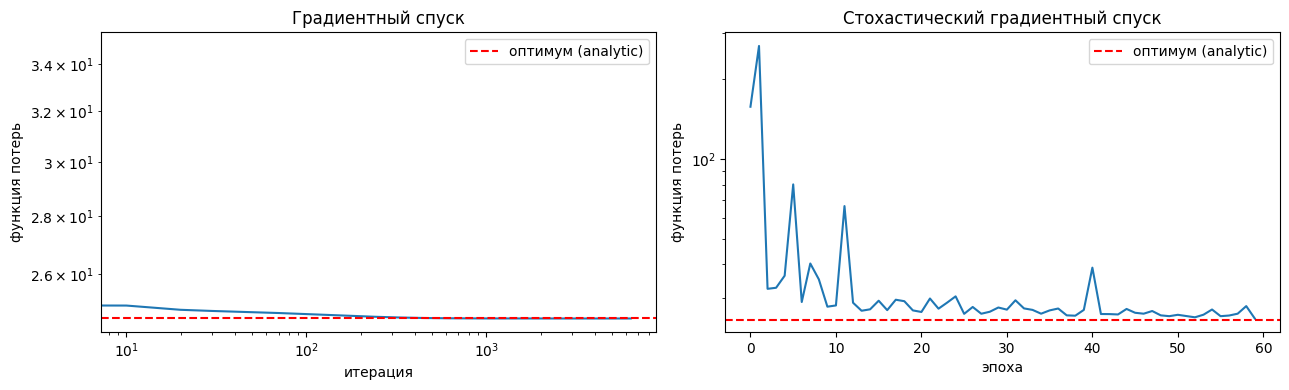

In [13]:

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
it, loss = zip(*models["своя: GD"].loss_history_)
ax[0].plot(it, loss); ax[0].set(xscale="log", yscale="log", xlabel="итерация", ylabel="функция потерь", title="Градиентный спуск")
ep, loss = zip(*models["своя: SGD"].loss_history_)
ax[1].plot(ep, loss); ax[1].set(yscale="log", xlabel="эпоха", ylabel="функция потерь", title="Стохастический градиентный спуск")
for a in ax: a.axhline(0.5 * mse(ytr, models["своя: analytic"].predict(Xtr)), color="r", ls="--", label="оптимум (analytic)"); a.legend()
plt.tight_layout(); plt.show()

## 4. Регуляризация: L2, L1, L1+L2
Сравниваем с `Ridge`, `Lasso`, `ElasticNet` из sklearn при одинаковом `α` (для Ridge — `n·α`, см. формулу выше).

In [14]:
n_tr = len(ytr)
alpha_l2, alpha_l1, alpha_en = 0.05, 0.05, 0.05

ridge = {
    "sklearn Ridge": Ridge(alpha=n_tr * alpha_l2).fit(Xtr, ytr),
    "своя: L2 analytic": MyLinearRegression("analytic", "l2", alpha_l2).fit(Xtr, ytr),
    "своя: L2 GD": MyLinearRegression("gd", "l2", alpha_l2, max_iter=200000).fit(Xtr, ytr),
    "своя: L2 SGD": MyLinearRegression("sgd", "l2", alpha_l2, max_iter=60, lr0=0.01, lr_decay=0.1).fit(Xtr, ytr),
}
print("L2 (Ridge), α =", alpha_l2)
report(ridge, Xtr, ytr, Xva, yva, "sklearn Ridge").round(6)

L2 (Ridge), α = 0.05


,MSE,MAE,R²,макс|Δ коэф|,нулей
модель,,,,,
sklearn Ridge,54.586776,5.913047,0.822139,0.00000,0
своя: L2 analytic,54.586776,5.913047,0.822139,0.00000,0
своя: L2 GD,54.586785,5.913047,0.822139,0.00005,0
своя: L2 SGD,55.214044,5.884017,0.820096,0.32621,0


In [15]:
lasso = {
    "sklearn Lasso": Lasso(alpha=alpha_l1, tol=1e-10, max_iter=100000).fit(Xtr, ytr),
    "своя: L1 GD": MyLinearRegression("gd", "l1", alpha_l1, max_iter=200000).fit(Xtr, ytr),
    "своя: L1 SGD": MyLinearRegression("sgd", "l1", alpha_l1, max_iter=60, lr0=0.01, lr_decay=0.1).fit(Xtr, ytr),
}
print("L1 (Lasso), α =", alpha_l1)
report(lasso, Xtr, ytr, Xva, yva, "sklearn Lasso").round(6)

L1 (Lasso), α = 0.05


,MSE,MAE,R²,макс|Δ коэф|,нулей
модель,,,,,
sklearn Lasso,54.125442,5.890299,0.823643,0.000000,14
своя: L1 GD,54.125443,5.890298,0.823643,0.000280,14
своя: L1 SGD,54.943679,5.872009,0.820977,0.915136,0


In [16]:
enet = {
    "sklearn ElasticNet": ElasticNet(alpha=alpha_en, l1_ratio=0.5, tol=1e-10, max_iter=100000).fit(Xtr, ytr),
    "своя: L1+L2 GD": MyLinearRegression("gd", "elasticnet", alpha_en, 0.5, max_iter=200000).fit(Xtr, ytr),
    "своя: L1+L2 SGD": MyLinearRegression("sgd", "elasticnet", alpha_en, 0.5, max_iter=60, lr0=0.01, lr_decay=0.1).fit(Xtr, ytr),
}
print("L1+L2 (ElasticNet), α =", alpha_en, ", ρ = 0.5")
report(enet, Xtr, ytr, Xva, yva, "sklearn ElasticNet").round(6)

L1+L2 (ElasticNet), α = 0.05 , ρ = 0.5


,MSE,MAE,R²,макс|Δ коэф|,нулей
модель,,,,,
sklearn ElasticNet,54.377191,5.903090,0.822822,0.000000,8
своя: L1+L2 GD,54.377199,5.903090,0.822822,0.000127,8
своя: L1+L2 SGD,55.078794,5.881083,0.820536,0.332381,0


**Вывод.** Для L2 аналитическое решение и GD совпадают с `Ridge`. Для L1 и L1+L2 градиентный спуск с проксимальным
шагом получает те же коэффициенты, что и `Lasso`/`ElasticNet`, причём часть коэффициентов обнуляется (отбор признаков).
SGD даёт близкий по качеству результат, но точных нулей почти нет — из-за шума случайных шагов коэффициенты колеблются вокруг нуля.

In [17]:

rows = []
for a in [0.0, 0.001, 0.01, 0.05, 0.1, 0.3, 1.0]:
    for pen in ["l2", "l1"]:
        m = MyLinearRegression("gd", pen, a, max_iter=100000).fit(Xtr, ytr)
        rows.append({"α": a, "штраф": pen, "MSE valid": mse(yva, m.predict(Xva)),
                     "ненулевых коэф.": int(np.sum(np.abs(m.coef_) > 1e-8))})
pd.DataFrame(rows).pivot(index="α", columns="штраф").round(3)

MSE valid         ненулевых коэф.    
штраф        l1      l2              l1  l2
α                                          
0.000    54.274  54.274              44  44
0.001    54.268  54.276              44  44
0.010    54.228  54.349              38  44
0.050    54.125  54.587              30  44
0.100    54.100  54.859              22  44
0.300    55.135  56.788              16  44
1.000    62.233  68.678               9  44

**Вывод.** Небольшая регуляризация почти не меняет качество, но при росте `α` L1 быстро обнуляет признаки,
а ошибка растёт. Регуляризация нужна не для снижения MSE на этих данных, а для устойчивости коэффициентов
при мультиколлинеарности и для отбора признаков. Значение `α` подбирается кросс-валидацией (следующая часть).

# Часть 3: кросс-валидация и итоговая модель
## 1. Кросс-валидация k-fold и leave-one-out
* **k-fold:** индексы перемешиваются, делятся на `k` почти равных частей; каждая часть по очереди служит проверочной.
* **Leave-one-out (LOO):** частный случай `k = n`: проверочная часть — один объект.

Нормализация внутри каждого фолда обучается **только на train-части фолда** (иначе информация из проверочной части
«подтекает» в обучение).

In [18]:
from sklearn.model_selection import KFold, LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def my_kfold(n, k=5, shuffle=True, seed=42):
    """Генератор пар (train_idx, valid_idx). Размеры частей отличаются не более чем на 1."""
    idx = np.arange(n)
    if shuffle:
        np.random.RandomState(seed).shuffle(idx)
    sizes = np.full(k, n // k)
    sizes[: n % k] += 1
    start = 0
    for size in sizes:
        valid = np.sort(idx[start:start + size])
        train = np.sort(np.concatenate([idx[:start], idx[start + size:]]))
        yield train, valid
        start += size

def my_loo(n):
    idx = np.arange(n)
    for i in range(n):
        yield np.delete(idx, i), idx[i:i + 1]

def my_cv_predict(make_model, X, y, splits, scaler_cls=ZScore):
    """Out-of-fold предсказания: каждый объект предсказывается моделью, которая его не видела."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    pred = np.zeros(len(y))
    for tr_idx, va_idx in splits:
        scaler = scaler_cls().fit(X[tr_idx]) if scaler_cls else None
        Xt = scaler.transform(X[tr_idx]) if scaler else X[tr_idx]
        Xv = scaler.transform(X[va_idx]) if scaler else X[va_idx]
        pred[va_idx] = make_model().fit(Xt, y[tr_idx]).predict(Xv)
    return pred

def cv_scores(y, pred):
    return {"MSE": mse(y, pred), "MAE": mae(y, pred), "R²": r2(y, pred)}

### Проверка разбиений и результатов относительно sklearn

In [19]:
n = len(y_all)

for (a_tr, a_va), (b_tr, b_va) in zip(my_kfold(n, 5, True, 42), KFold(5, shuffle=True, random_state=42).split(X_all)):
    assert np.array_equal(a_va, b_va) and np.array_equal(a_tr, b_tr)
print("k-fold: разбиения совпадают с sklearn (5 фолдов, перемешивание, seed=42)")

own_pred = my_cv_predict(lambda: MyLinearRegression("analytic"), X_all, y_all, my_kfold(n, 5, True, 42))
ref_pred = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), X_all, y_all,
                             cv=KFold(5, shuffle=True, random_state=42))
print(f"5-fold MSE: своя = {mse(y_all, own_pred):.6f} | sklearn = {mean_squared_error(y_all, ref_pred):.6f} "
      f"| макс|Δ предсказаний| = {np.abs(own_pred - ref_pred).max():.2e}")

k-fold: разбиения совпадают с sklearn (5 фолдов, перемешивание, seed=42)
5-fold MSE: своя = 50.565716 | sklearn = 50.565716 | макс|Δ предсказаний| = 8.19e-12


In [20]:

m = 600
sub = np.random.RandomState(0).choice(n, m, replace=False)
Xs, ys = X_all[sub], y_all[sub]
for (a_tr, a_va), (b_tr, b_va) in zip(my_loo(m), LeaveOneOut().split(Xs)):
    assert np.array_equal(a_tr, b_tr) and np.array_equal(a_va, b_va)
own_loo = my_cv_predict(lambda: MyLinearRegression("analytic"), Xs, ys, my_loo(m))
ref_loo = cross_val_predict(make_pipeline(StandardScaler(), LinearRegression()), Xs, ys, cv=LeaveOneOut())
print(f"LOO (m={m}) MSE: своя = {mse(ys, own_loo):.6f} | sklearn = {mean_squared_error(ys, ref_loo):.6f} "
      f"| макс|Δ| = {np.abs(own_loo - ref_loo).max():.2e}")

LOO (m=600) MSE: своя = 50.898339 | sklearn = 50.898339 | макс|Δ| = 9.02e-13


**LOO для всей выборки.** Для МНК остатки LOO считаются без переобучения: `e_i^(LOO) = e_i / (1 − h_ii)`, где
`h_ii` — диагональ «шляпной» матрицы `H = X(XᵀX)⁺Xᵀ`. Проверим формулу на тех же 600 объектах и посчитаем на всех данных.

In [21]:
def loo_ols_closed_form(X, y):
    """LOO-предсказания МНК по формуле через диагональ шляпной матрицы (без повторных обучений)."""
    Xa = np.column_stack([np.ones(len(y)), X])
    U, s, _ = np.linalg.svd(Xa, full_matrices=False)
    U = U[:, s > s.max() * 1e-10]
    h = np.sum(U ** 2, axis=1)
    fitted = U @ (U.T @ y)
    return y - (y - fitted) / (1 - h)

print(f"LOO по формуле на тех же {m} объектах: {mse(ys, loo_ols_closed_form(Xs, ys)):.6f} "
      f"(перебором: {mse(ys, own_loo):.6f})")
print(f"LOO MSE на всех {n} объектах (МНК, формула): {mse(y_all, loo_ols_closed_form(X_all, y_all)):.4f}")

LOO по формуле на тех же 600 объектах: 50.898339 (перебором: 50.898339)
LOO MSE на всех 9332 объектах (МНК, формула): 50.7751


**Вывод.** Свои `my_kfold` и `my_loo` дают те же разбиения, что и sklearn, а out-of-fold предсказания и MSE
совпадают с `cross_val_predict` до ошибок округления. Простой МНК на исходных признаках даёт
CV-MSE около 50 — это «нулевая линия», с которой мы сравниваем всё дальнейшее.

### Подбор силы регуляризации кросс-валидацией

In [22]:
rows = []
for a in [1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
    p = my_cv_predict(lambda: MyLinearRegression("analytic", "l2", a), X_all, y_all, my_kfold(n, 5, True, 42))
    rows.append({"α (L2)": a, **cv_scores(y_all, p)})
pd.DataFrame(rows).set_index("α (L2)").round(4)

,MSE,MAE,R²
α (L2),,,
0.0001,50.5653,5.7133,0.8299
0.0010,50.5647,5.7136,0.8299
0.0100,50.6390,5.7191,0.8297
0.1000,51.2539,5.7513,0.8276
1.0000,65.2996,6.6118,0.7804


На исходных признаках регуляризация почти не влияет (MSE ≈ 50 при любом разумном `α`): проблема не в переобучении,
а в том, что признаков недостаточно для этой зависимости. Поэтому дальше усложняем **признаки**, оставаясь в классе
линейных моделей (линейность по параметрам).

## 2. Признаки: что показал EDA
* В EDA `RiskScore` двугорбый, а зависимости от кредитного рейтинга, дохода и т. п. ступенчатые, с насыщением.
* Простая линейная регрессия на исходных признаках даёт MSE ≈ 50, то есть сырых признаков недостаточно.

По лекции линейная регрессия линейна по параметрам, но не обязана быть линейной по признакам, поэтому нелинейность
переносим в признаки. Чтобы найти, **где** зависимость меняется ступенькой, используем только линейную регрессию:
для каждого признака строим «ступеньки» `1[x ≥ t]` на мелкой сетке порогов `t` и обучаем **свою** регрессию с
L1-штрафом (`MyLinearRegression`, градиентный спуск). L1 оставляет ненулевые коэффициенты только у нужных порогов.

In [23]:
def grid(lo, hi, step):
    return list(np.round(np.arange(lo, hi + 1e-9, step), 6))

THRESHOLD_GRID = {
    "CreditScore": grid(400, 840, 10), "DebtToIncomeRatio": grid(0.05, 0.8, 0.025),
    "CreditCardUtilizationRate": grid(0.05, 0.95, 0.05), "LengthOfCreditHistory": grid(1, 29, 1),
    "AnnualIncome": grid(10_000, 200_000, 5_000),
    "NetWorth": [round(float(v), -2) for v in np.exp(np.linspace(np.log(5_000), np.log(1_500_000), 45))],
}

def l1_threshold_table(df, y, alpha=0.05, min_coef=0.25):
    """L1-регрессия по ступенькам на сетке порогов. Возвращает по каждому признаку пороги с заметным коэффициентом."""
    names, cols = [], []
    for c, ts in THRESHOLD_GRID.items():
        for t in ts:
            names.append((c, t))
            cols.append((df[c].to_numpy() >= t).astype(float))
    raw = pd.get_dummies(df.drop(columns=["RiskScore", "ApplicationDate"], errors="ignore"),
                         columns=CATEGORICAL, drop_first=True, dtype=float).to_numpy(float)
    Z = ZScore().fit_transform(np.hstack([raw, np.column_stack(cols)]))
    model = MyLinearRegression("gd", "l1", alpha=alpha, max_iter=40000, tol=1e-9).fit(Z, y)
    coef = pd.Series(model.coef_[raw.shape[1]:])
    out = {}
    for c in THRESHOLD_GRID:
        idx = [i for i, (cc, _) in enumerate(names) if cc == c]
        sub = coef.iloc[idx]
        out[c] = {names[i][1]: round(float(v), 2) for i, v in sub[sub.abs() > min_coef].items()}
    return out

CATEGORICAL = ["MaritalStatus", "HomeOwnershipStatus", "LoanPurpose", "EmploymentStatus", "EducationLevel"]
found = l1_threshold_table(data, y_all)
for c, d_ in found.items():
    print(f"{c:27s}", d_)

CreditScore                 {np.float64(570.0): -0.25, np.float64(600.0): -1.29, np.float64(650.0): -1.44, np.float64(670.0): -0.31, np.float64(700.0): -1.36, np.float64(750.0): -1.38}
DebtToIncomeRatio           {np.float64(0.2): 0.98, np.float64(0.3): 0.82, np.float64(0.4): 0.53, np.float64(0.475): 0.33, np.float64(0.5): 0.27}
CreditCardUtilizationRate   {np.float64(0.2): 0.37}
LengthOfCreditHistory       {np.float64(3.0): -0.27, np.float64(6.0): -0.37, np.float64(7.0): -0.39, np.float64(10.0): -0.33}
AnnualIncome                {np.float64(20000.0): -0.47, np.float64(30000.0): -1.26, np.float64(35000.0): -0.4, np.float64(45000.0): -0.55, np.float64(50000.0): -1.35, np.float64(55000.0): -0.5, np.float64(70000.0): -0.27, np.float64(80000.0): -1.48, np.float64(90000.0): -0.51, np.float64(105000.0): -0.78, np.float64(120000.0): -1.11, np.float64(125000.0): -0.39, np.float64(145000.0): -0.41}
NetWorth                    {51600.0: -0.73, 58700.0: -0.29, 98600.0: -0.69, 244300.0: -0.62, 27

L1 выделяет «круглые» пороги с почти одинаковыми по величине коэффициентами:
`CreditScore` — 600/650/700/750 (коэффициент ≈ −1.4 у каждого), `AnnualIncome` — 30k/50k/80k/120k,
`DebtToIncomeRatio` — 0.2/0.3/0.4/0.5, `NetWorth` — около 50k/100k/250k/500k (сетка логарифмическая, поэтому значения
приближённые). У `CreditCardUtilizationRate` и `LengthOfCreditHistory` эффект слабее и пороги выделяются менее чётко;
их уточним ниже.

Равные по величине коэффициенты у соседних порогов означают, что вклад признака растёт на одну и ту же величину с
каждым пройденным порогом. Поэтому каждый признак заменяем **уровнем** — числом пройденных порогов (0…4).
Дополнительно берём три бинарных признака: банкротство, прошлые просрочки, «не работает по найму».

In [24]:
LEVEL_THRESHOLDS = {
    "CreditScore": [600, 650, 700, 750],
    "DebtToIncomeRatio": [0.2, 0.3, 0.4, 0.5],
    "AnnualIncome": [30_000, 50_000, 80_000, 120_000],
    "NetWorth": [50_000, 100_000, 250_000, 500_000],
    "CreditCardUtilizationRate": [0.2, 0.4, 0.6, 0.8],
    "LengthOfCreditHistory": [3, 6, 7, 10],
}

def make_levels(df):
    """Уровни: сколько порогов пройдено (0…4) + три бинарных признака."""
    L = pd.DataFrame(index=df.index)
    for c, ts in LEVEL_THRESHOLDS.items():
        L[c + "_level"] = sum((df[c] >= t).astype(float) for t in ts)
    L["BankruptcyHistory"] = df["BankruptcyHistory"].astype(float)
    L["PreviousLoanDefaults"] = df["PreviousLoanDefaults"].astype(float)
    L["NotEmployed"] = (df["EmploymentStatus"] != "Employed").astype(float)
    return L

levels_all = make_levels(data).to_numpy(float)
base_ols = MyLinearRegression("analytic").fit(levels_all, y_all)
print("МНК на 9 признаках-уровнях: MSE на train =", round(mse(y_all, base_ols.predict(levels_all)), 2))

МНК на 9 признаках-уровнях: MSE на train = 31.19


## 3. Две группы заявок
`RiskScore` двугорбый. Проверим, нет ли двух групп с разной зависимостью от уровней: начинаем с разбиения по медиане и
несколько раз повторяем «обучить по регрессии на группу → отнести каждую заявку к группе, чей прогноз ближе».
Все регрессии — свой `MyLinearRegression`.

In [25]:
def two_groups(L, y, n_iter=100):
    upper = y > np.median(y)
    for _ in range(n_iter):
        low = MyLinearRegression("analytic").fit(L[~upper], y[~upper])
        high = MyLinearRegression("analytic").fit(L[upper], y[upper])
        new = np.abs(y - high.predict(L)) < np.abs(y - low.predict(L))
        if np.array_equal(new, upper):
            break
        upper = new
    return upper, low, high

upper, low_m, high_m = two_groups(levels_all, y_all)
level_names = list(make_levels(data).columns)
tab = pd.DataFrame({"группа 1 (ниже)": low_m.coef_, "группа 2 (выше)": high_m.coef_}, index=level_names)
tab["отношение"] = tab.iloc[:, 1] / tab.iloc[:, 0]
tab.loc["(свободный член)"] = [low_m.intercept_, high_m.intercept_, high_m.intercept_ / low_m.intercept_]
print(f"доля группы 2: {upper.mean():.3f} | MSE внутри групп (train): "
      f"{mse(y_all, np.where(upper, high_m.predict(levels_all), low_m.predict(levels_all))):.2f}")
tab.round(2)

доля группы 2: 0.492 | MSE внутри групп (train): 6.37


,группа 1 (ниже),группа 2 (выше),отношение
CreditScore_level,-2.89,-4.17,1.44
DebtToIncomeRatio_level,1.54,2.25,1.46
AnnualIncome_level,-1.88,-2.51,1.34
NetWorth_level,-1.57,-2.24,1.43
CreditCardUtilizationRate_level,0.97,1.34,1.39
LengthOfCreditHistory_level,-0.72,-1.06,1.47
BankruptcyHistory,9.62,13.72,1.43
PreviousLoanDefaults,1.83,2.76,1.51
NotEmployed,2.36,3.31,1.40
(свободный член),50.25,71.03,1.41


**Вывод.** Две группы действительно есть, и коэффициенты второй группы почти во всех строках в **одно и то же число раз
(≈ 1.4)** больше, чем у первой, включая свободный член. То есть `RiskScore` = «сумма баллов за уровни» ×
множитель, который принимает одно из двух значений. Внутри группы MSE всего ≈ 6, то есть уровни описывают
зависимость почти полностью. Остаётся понять, какую группу даёт каждая заявка.

**Уточняем пороги в каждой группе.** Внутри группы ступенчатый сигнал не «размывается» другой группой, поэтому
пороги видны чище (особенно у `CreditCardUtilizationRate` и `LengthOfCreditHistory`).

In [26]:
for name, mask in [("группа 1", ~upper), ("группа 2", upper)]:
    print(name)
    for c, d_ in l1_threshold_table(data[mask].reset_index(drop=True), y_all[mask], alpha=0.03, min_coef=0.5).items():
        if c in ("CreditCardUtilizationRate", "LengthOfCreditHistory"):
            print(f"  {c:27s}", d_)

группа 1
  CreditCardUtilizationRate   {}
  LengthOfCreditHistory       {}
группа 2
  CreditCardUtilizationRate   {np.float64(0.2): 0.62, np.float64(0.4): 0.52}
  LengthOfCreditHistory       {}


Внутри групп сигнал по этим двум признакам слабый, поэтому L1 даёт лишь отдельные пороги (`CreditCardUtilizationRate` —
0.2 и 0.4). По всей выборке для `LengthOfCreditHistory` L1 находил 3, 6, 7, 10. Выбираем между кандидатами по CV
итоговой модели (она описана в разделах 4–5 ниже; здесь запускаем её для сравнения).

In [27]:
def build_X(df):
    gate = gate_features(df)
    return np.hstack([make_levels(df).to_numpy(float), gate.to_numpy(float)])

def cv_variant(utilization, history):
    LEVEL_THRESHOLDS["CreditCardUtilizationRate"], LEVEL_THRESHOLDS["LengthOfCreditHistory"] = utilization, history
    p = my_cv_predict(lambda: ApprovalLinearModel(9), build_X(data), y_all, my_kfold(n, 5, True, 0), None)
    return mse(y_all, p)

## 4. Какая это группа? Оценка «индекса» по линейной регрессии
Нужно для новой заявки оценить вероятность `p` попасть в группу 2. Делаем это тоже линейной регрессией:
1. Метка группы (0/1) регрессируется на все исходные признаки (+ `Age²`, чтобы поймать U-образную зависимость от
   возраста). Получаем линейный индекс `s(x)`.
2. Метка 0/1 «насыщается»: у явных случаев линейная регрессия по метке даёт значения вне `[0, 1]` и искажает
   коэффициенты. Поэтому регрессию переобучаем только на заявках, у которых индекс ещё внутри `(0.1, 0.9)`
   (3 прохода) — приём «усечённой» регрессии.
3. Из индекса получаем вероятность `p = f(s)` — кусочно-линейная функция (линейная регрессия по hinge-признакам
   индекса), обрезанная в `[0, 1]`.

**Итоговая регрессия.** Если `L` — вектор уровней, то в группе 1 прогноз `L·w₀`, в группе 2 — `L·w₁`. Когда группа
неизвестна, лучший по MSE прогноз — `(1−p)·L·w₀ + p·L·w₁ = L·w₀ + p·L·(w₁−w₀)`. Он **линеен** по признакам
`[L, p, p·L]` (`p` добавляется ещё и отдельно как сдвиг), поэтому итоговая модель — одна обычная линейная регрессия.

In [28]:
def gate_features(df, columns=None):
    """Признаки для оценки индекса: исходные числовые, one-hot для категорий и Age²."""
    X = df.drop(columns=["RiskScore", "ApplicationDate", "ID"], errors="ignore")
    X = pd.get_dummies(X, columns=CATEGORICAL, drop_first=True, dtype=float)
    X["AgeSquared"] = df["Age"].astype(float) ** 2
    if columns is not None:
        X = X.reindex(columns=columns, fill_value=0.0)
    return X

def ridge(a, n_eff):
    """L2-регуляризованный аналитический МНК; `a` — сила штрафа в единицах Σ(ошибка²) + a·‖w‖²."""
    return MyLinearRegression("analytic", "l2", a / n_eff)

def hinge(z, knots):
    z = np.clip(z, knots[0], knots[-1])
    return np.column_stack([z] + [np.maximum(z - k, 0.0) for k in knots[1:-1]])

class ApprovalLinearModel:
    """Одна итоговая линейная регрессия на [L, p, p·L]; p оценивается линейными регрессиями (см. описание выше)."""

    def __init__(self, n_levels, alpha_gate=3.0, trim_rounds=3, p_low=0.1, p_high=0.9, link_knots=12):
        self.n_levels, self.alpha_gate, self.trim_rounds = n_levels, alpha_gate, trim_rounds
        self.p_low, self.p_high, self.link_knots = p_low, p_high, link_knots

    def _split(self, X):
        return X[:, :self.n_levels], X[:, self.n_levels:]

    def _p(self, A):
        s = self.gate_.predict(A)
        return np.clip(self.link_.predict(hinge(s, self.knots_)), 0.0, 1.0)

    def fit(self, X, y):
        L, G = self._split(np.asarray(X, float))
        y = np.asarray(y, float)
        upper, _, _ = two_groups(L, y)
        label = upper.astype(float)
        self.scaler_ = ZScore().fit(G)
        A = self.scaler_.transform(G)
        self.gate_ = ridge(self.alpha_gate, len(y)).fit(A, label)
        s = self.gate_.predict(A)
        for _ in range(self.trim_rounds):
            keep = (s > self.p_low) & (s < self.p_high)
            self.gate_ = ridge(self.alpha_gate, keep.sum()).fit(A[keep], label[keep])
            s = self.gate_.predict(A)
        self.knots_ = np.unique(np.quantile(s, np.linspace(0, 1, self.link_knots)))
        self.link_ = ridge(1e-3, len(y)).fit(hinge(s, self.knots_), label)
        p = self._p(A)
        self.final_ = MyLinearRegression("analytic").fit(np.column_stack([L, p, L * p[:, None]]), y)
        return self

    def predict(self, X):
        L, G = self._split(np.asarray(X, float))
        p = self._p(self.scaler_.transform(G))
        return self.final_.predict(np.column_stack([L, p, L * p[:, None]]))

Сравним варианты порогов для двух слабых признаков по CV итоговой модели.

In [29]:
cands = {
    "util 0.2/0.4/0.6/0.8, history 3/6/7/10": ([0.2, 0.4, 0.6, 0.8], [3, 6, 7, 10]),
    "util 0.2/0.4/0.6/0.8, history 3/5/7/10": ([0.2, 0.4, 0.6, 0.8], [3, 5, 7, 10]),
    "util 0.2/0.4/0.6,     history 3/5/7/10": ([0.2, 0.4, 0.6], [3, 5, 7, 10]),
}
res = {k_: cv_variant(*v) for k_, v in cands.items()}
print(pd.Series(res).round(3))
best = min(res, key=res.get)
LEVEL_THRESHOLDS["CreditCardUtilizationRate"], LEVEL_THRESHOLDS["LengthOfCreditHistory"] = cands[best]
print("выбрано:", best)

util 0.2/0.4/0.6/0.8, history 3/6/7/10    18.232
util 0.2/0.4/0.6/0.8, history 3/5/7/10    18.243
util 0.2/0.4/0.6,     history 3/5/7/10    18.245
dtype: float64
выбрано: util 0.2/0.4/0.6/0.8, history 3/6/7/10


In [30]:
train_gate = gate_features(data)
GATE_COLUMNS = list(train_gate.columns)
X_model = np.hstack([make_levels(data).to_numpy(float), train_gate.to_numpy(float)])
N_LEVELS = len(level_names)
print("уровней:", N_LEVELS, "| признаков для индекса:", train_gate.shape[1])

уровней: 9 | признаков для индекса: 45


## 5. Кросс-валидация итоговой модели
Все шаги (разметка групп, индекс, `p`, итоговая регрессия) заново обучаются внутри каждого фолда (`my_kfold`, seed = 0).

In [31]:
def row(name, make_model, X, scaler_cls=None):
    p = my_cv_predict(make_model, X, y_all, my_kfold(n, 5, True, 0), scaler_cls)
    return {"модель": name, **cv_scores(y_all, p), "MAPE": mape(y_all, p)}

rows = [
    row("1. МНК на исходных признаках", lambda: MyLinearRegression("analytic"), train_gate.to_numpy(float), ZScore),
    row("2. МНК на 9 признаках-уровнях", lambda: MyLinearRegression("analytic"), X_model[:, :N_LEVELS]),
    row("3. + вероятность группы (итоговая)", lambda: ApprovalLinearModel(N_LEVELS), X_model),
]
cv_table = pd.DataFrame(rows).set_index("модель")
cv_table.round(4)

,MSE,MAE,R²,MAPE
модель,,,,
1. МНК на исходных признаках,50.6373,5.7155,0.8297,0.1342
2. МНК на 9 признаках-уровнях,31.2930,4.1045,0.8947,0.0949
3. + вероятность группы (итоговая),18.2319,2.9411,0.9387,0.0682


**Вывод.** Уровни порогов дают огромный выигрыш (50 → ≈ 31 уже на 9 признаках), а вероятность группы и
произведения `p·L` дают ещё один шаг, примерно до 18. Оставшаяся ошибка складывается из шума внутри группы (≈ 6)
и неопределённости самой группы: для заявок «на границе» группа определяется неточно.

In [32]:

rows = []
for a in [1.0, 3.0, 10.0, 30.0]:
    for lo_, hi_ in [(0.1, 0.9), (0.03, 0.97)]:
        p = my_cv_predict(lambda: ApprovalLinearModel(N_LEVELS, alpha_gate=a, p_low=lo_, p_high=hi_), X_model, y_all,
                          my_kfold(n, 5, True, 0), None)
        rows.append({"α индекса": a, "окно усечения": f"({lo_}, {hi_})", "MSE": mse(y_all, p)})
sens = pd.DataFrame(rows)
sens.pivot(index="α индекса", columns="окно усечения", values="MSE").round(3)

окно усечения,"(0.03, 0.97)","(0.1, 0.9)"
α индекса,,
1.0,18.248,18.223
3.0,18.266,18.232
10.0,18.298,18.295
30.0,18.421,18.461


## 6. Предсказание для test.csv и файл решения

In [33]:
test = pd.read_csv(f"{DATA_DIR}/test.csv")
X_test = np.hstack([make_levels(test).to_numpy(float), gate_features(test, GATE_COLUMNS).to_numpy(float)])
assert np.isfinite(X_test).all() and X_test.shape[1] == X_model.shape[1]

final_model = ApprovalLinearModel(N_LEVELS).fit(X_model, y_all)
pred_test = final_model.predict(X_test)

submission = pd.DataFrame({"ID": test["ID"], "RiskScore": pred_test})
assert len(submission) == len(test) == 5000 and submission["ID"].is_unique
assert np.isfinite(submission["RiskScore"]).all()
submission.to_csv("submission.csv", index=False)
print("train RiskScore: ", y_all.min().round(1), "-", y_all.max().round(1), "| среднее", y_all.mean().round(2))
print("test прогноз:    ", pred_test.min().round(1), "-", pred_test.max().round(1), "| среднее", pred_test.mean().round(2))
submission.head()

train RiskScore:  14.8 - 97.6 | среднее 48.31
test прогноз:     22.1 - 93.5 | среднее 48.19


,ID,RiskScore
0,0,33.120425
1,1,53.691415
2,2,30.075416
3,3,34.948461
4,4,32.931918


Файл `submission.csv` (колонки `ID,RiskScore`) загружается на Kaggle. На Kaggle ошибка обычно немного выше,
чем CV на train.